In [33]:
# 데이터 표와 숫자를 다루는 도구
import numpy as np
import pandas as pd
# 사진을 열고 크기를 조절하는 도구
import matplotlib.pyplot as plt 
from PIL import Image # 사진재료 열기 
# 파일과 폴더 위치를 관리하는 도구
import os
import pathlib 
# 딥러닝 주방을 준비하는 도구
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [34]:
# TrashNet 데이터셋 다운로드 GitHub 내려받고 압출풀기

# GitHub 저장소 주소 
# dataset_url은 인터넷에서 사진 자료를 가져올 위치를 기억하는 변수
datast_url = "https://github.com/garythung/trashnet/archive/refs/heads/master.zip"

# 압축파일 저장할 이름
# fname: 내 컴퓨터에 저장할 압축파일 이름
# origin: 압축파일을 가져올 인터넷 주소
# extract=True: 다운로드한 ZIP 파일의 압축을 자동으로 풀어줌
zip_path = tf.keras.utils.get_file(
    fname="trashnet.zip",
    origin=datast_url ,
    extract=True
)

# 압축이 풀린 데이터 폴더 위치 확인
# zip_path가 저장된 위치를 기준으로 trashnet-master 폴더를 찾음
data_dir = pathlib.Path(zip_path).parent / "trashnet_extracted"  / "trashnet-master" /"data"
# 폴더 제대로 만들었는지 확인
# True가 나오면 폴더를 정상적으로 찾았다는 뜻

# 압축파일이 저장된 폴더 안에 실제로 어떤 항목이 있는지 확인
print("압출파일 위치:", pathlib.Path(zip_path).parent)
# 압축파일이 저장된 위치에 실제로 들어 있는 파일과 폴더 이름 확인
for item in pathlib.Path(zip_path).parent.iterdir():
    print(item.name)

print("데이터 폴더 위치 :", data_dir)
print("폴더 존재 여부:", data_dir.exists())



압출파일 위치: C:\Users\human-01\.keras\datasets
fashion-mnist
trashnet.zip
trashnet_extracted
데이터 폴더 위치 : C:\Users\human-01\.keras\datasets\trashnet_extracted\trashnet-master\data
폴더 존재 여부: True


In [3]:
# 쓰레기 이미지 들어있는지 확인단계

# glob("*")은 지정한 폴더 바로 아래에 있는 항목을 모두 찾는 기능
# is_dir()는 해당 항목이 파일이 아니라 폴더인지 확인
image_data_dir = data_dir / "dataset-resized" / "dataset-resized"
class_folders = [folder for folder in image_data_dir.glob("*") if folder.is_dir()]

# [2] 찾은 폴더의 이름을 출력
# 각 폴더 이름이 쓰레기 이미지의 분류 기준이 됨
print("쓰레기 분류 폴더 목록:")

for folder in class_folders:
    print("-", folder.name)
    
# 전체 분류 종류가 몇 개인지 확인
print("전체 분류 종류:", len(class_folders))



쓰레기 분류 폴더 목록:
- cardboard
- glass
- metal
- paper
- plastic
- trash
전체 분류 종류: 6


In [4]:
# 현재 data_dir 이 가리키는 실제 위치확인
print("현재 데이터 경로:", data_dir)
print("폴더 존재 여부:", data_dir.exists())

#data_dir 바로 아래 항목 확인
if data_dir.exists():
    for item in data_dir.iterdir():
        print("폴더 또는 파일:", item.name)

# 다운로드 폴더 부터 실제 구조확인
print("\n다운로드 폴더 내부 구조:")

base_dir = pathlib.Path(zip_path).parent

for path in base_dir.rglob("*"):
    if path.is_dir():
        print(path)        

현재 데이터 경로: C:\Users\human-01\.keras\datasets\trashnet_extracted\trashnet-master\data
폴더 존재 여부: True
폴더 또는 파일: constants.py
폴더 또는 파일: dataset-resized
폴더 또는 파일: dataset-resized.zip
폴더 또는 파일: one-indexed-files-notrash_test.txt
폴더 또는 파일: one-indexed-files-notrash_train.txt
폴더 또는 파일: one-indexed-files-notrash_val.txt
폴더 또는 파일: one-indexed-files.txt
폴더 또는 파일: resize.py
폴더 또는 파일: zero-indexed-files.txt

다운로드 폴더 내부 구조:
C:\Users\human-01\.keras\datasets\fashion-mnist
C:\Users\human-01\.keras\datasets\trashnet_extracted
C:\Users\human-01\.keras\datasets\trashnet_extracted\trashnet-master
C:\Users\human-01\.keras\datasets\trashnet_extracted\trashnet-master\data
C:\Users\human-01\.keras\datasets\trashnet_extracted\trashnet-master\data\dataset-resized
C:\Users\human-01\.keras\datasets\trashnet_extracted\trashnet-master\data\dataset-resized\dataset-resized
C:\Users\human-01\.keras\datasets\trashnet_extracted\trashnet-master\data\dataset-resized\__MACOSX
C:\Users\human-01\.keras\datasets\trashnet_ext

In [5]:
# 실제 이미지가 들어있는 ZIP 파일 위치지정
image_zip = data_dir / "dataset-resized.zip"

#압축을 풀어 저장할 폴더 지정
image_dir = data_dir / "dataset-resized"

# zip 파일 압축풀기

import zipfile 

with zipfile.ZipFile(image_zip, "r") as zip_ref:
    zip_ref.extractall(image_dir)
    
# 압축 해제된 폴더와 파일 확인
for item in image_dir.iterdir():
    print(item.name)    

dataset-resized
__MACOSX


In [6]:
# 이미개수 확인 및 데이터 분포 분석

# 딕셔러니 분류 이름과 사진 개수를 짝지어 저장하는 자료형
class_counts = {}

# 6개 분류 폴더 하나씩 확인
for folder in class_folders:
    # 해당 폴더 안의 이미지 파일만 찾기
    # jpg, jpeg, png 확장자를 가진 파일을 대상으로함.
    image_files = list(folder.glob("*.jpg"))
    image_files += list(folder.glob("*.jpeg"))
    image_files += list(folder.glob("*png"))
    
    # 폴더 이름을 기준으로 이미지 개수 저장
    class_counts[folder.name] = len(image_files)
    
 # 이미지 개수 출력
print("분류별 이미지 개수")
 
for class_name, count in class_counts.items():
    print(class_name, ":", count, "장")

분류별 이미지 개수
cardboard : 403 장
glass : 501 장
metal : 410 장
paper : 594 장
plastic : 482 장
trash : 137 장


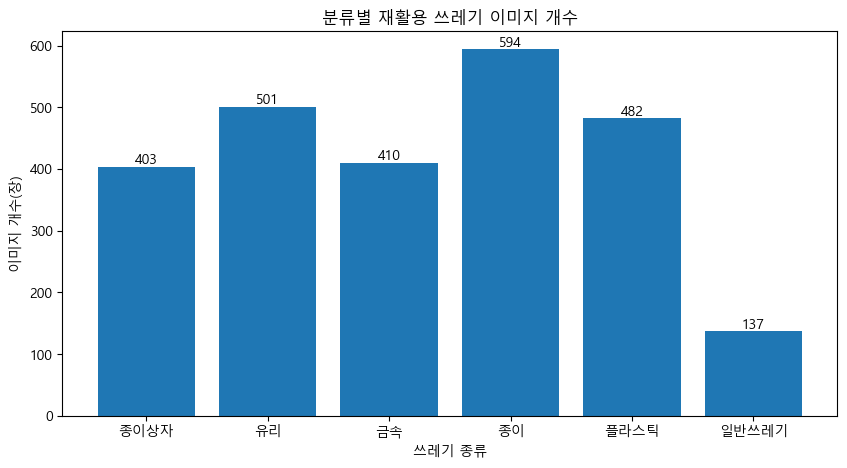

In [7]:
# 시각화

# 한글이 그래프에서 깨지지 않도록 한글 글꼴 설정
plt.rcParams["font.family"] = "Malgun Gothic"

# 그래프에서 마이너스 기호가 깨지는 현상 방지
plt.rcParams["axes.unicode_minus"] = False

#그래프 크기 설정  가로10,세로5 그래프 공간 생성
plt.figure(figsize=(10,5))

# 분류 이름과 이미지 개수를 막대그래프로 표현 plt.bar(): 막대그래프 그리기 , 영어 폴더 이름 한글 변환
korean_names = {
    "cardboard": "종이상자",
    "glass": "유리",
    "metal": "금속",
    "paper": "종이",
    "plastic": "플라스틱",
    "trash": "일반쓰레기"
}


plt.bar(
    [korean_names[name] for name in class_counts.keys()],
 class_counts.values())

# 그래프 제목과 축 이름 설정
plt.title("분류별 재활용 쓰레기 이미지 개수")
plt.xlabel("쓰레기 종류")
plt.ylabel("이미지 개수(장)")

# 막대위에 이미지 개수 표시
for index, count in enumerate(class_counts.values()):
    plt.text(index, count +5, str(count), ha="center")
    
# 그래프 출력
plt.show()


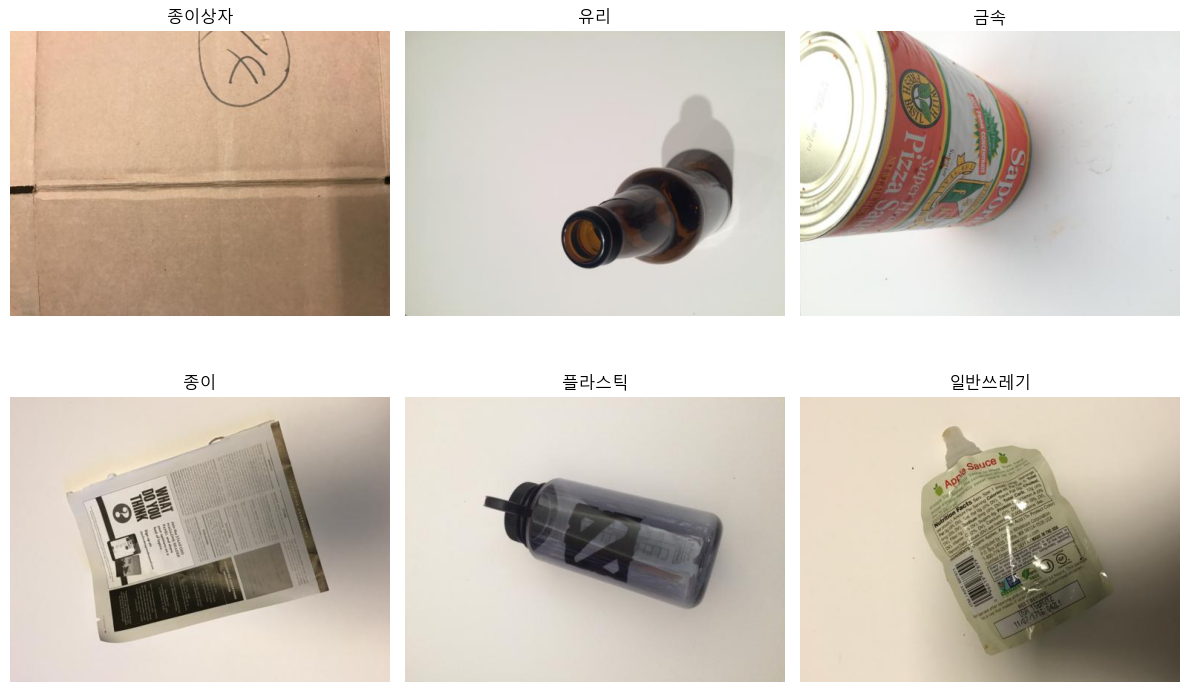

In [8]:
# 실제 쓰레기 사진 미리보기
# 그래프 화면 크기 설정
plt.figure(figsize=(12,8))
# 6개 분류 폴더에 사진 하나씩 가져와 화면에 표시

for index, folder in enumerate(class_folders):
    # jpg 사진찾기 
    image_path = next(folder.glob("*.jpg"))
    #사진 열기 
    img = Image.open(image_path)
    # 6개 사진  2행 3열로 배치
    plt.subplot(2,3,index +1)
    # 사진 표시
    plt.imshow(img)
    # 폴더 이름 한글로 변환해서 제목표시
    plt.title(korean_names[folder.name])
    #사진 주변 눈금제거
    plt.axis("off")
    
# 사진 6장 화면 출력
plt.tight_layout()
plt.show()

In [9]:
# 이미지 크기 확인
# jpg 사진 하나 선택
sample_image_path = next(class_folders[0].glob("*.jpg"))
# 이미지 열기
sample_image = Image.open(sample_image_path)
#  가로 세로 크기 확인
print ("원본 이미지 크기:", sample_image.size)
#이미지 색상 확인
print("이미지 색상 모드:", sample_image.mode)


원본 이미지 크기: (512, 384)
이미지 색상 모드: RGB


In [10]:
# 이미지 크기 조정 및 데이터셋 불렁로기
# 학습용 이미지  가로128, 세로 128
IMG_SIZE = (128, 128)

# 한번에 학습할 이미지 수 설정
BATCH_SIZE = 32

# 이미지 데이터 불러올때 사용할 함수 
train_ds = tf.keras.utils.image_dataset_from_directory(
    image_data_dir, #실제 이미지 폴더
    validation_split=0.2, # 20% 검증용
    subset="training", #학습용 불러오기
    seed=123, # 나누는 기준 
    image_size=IMG_SIZE, # 128,128
    batch_size=BATCH_SIZE # 32장
)

# 검증용 이미지 불러오기
val_ds = tf.keras.utils.image_dataset_from_directory(
    image_data_dir,
    validation_split=0.2,
    subset="validation",          # 검증용 데이터 불러오기
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# 분류 순서 확인
class_names = train_ds.class_names

print("분류 목록:", class_names)
print("분류 개수:", len(class_names))


Found 2527 files belonging to 6 classes.
Using 2022 files for training.
Found 2527 files belonging to 6 classes.
Using 505 files for validation.
분류 목록: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
분류 개수: 6


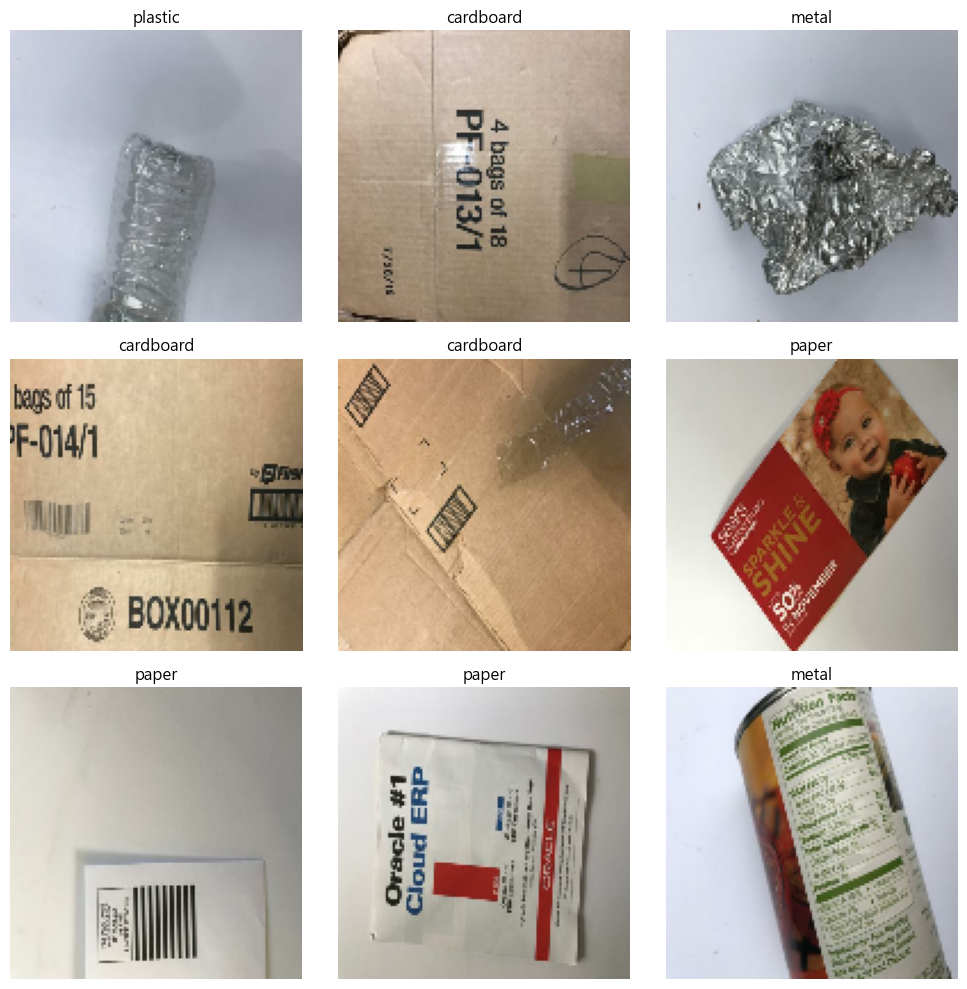

In [11]:
# 학습 이미지 확인하기
# images 에는 사진, labels 는 정답 번호가 들어있음

for images, labels in train_ds.take(1): #train_ds.take(1): 학습 데이터 묶음 중 첫 번째 묶음 하나 가져오기.
    #사진 9장 보여줄 그래프 공간 만들기
    plt.figure(figsize=(10,10))
    #사진 9장 하나씩 화면에 표시
    for i in range(9):
        
        #3행 3열 중 위치 지정
        ax = plt.subplot(3,3,i+1)
        #이미지 필셀값 화면 표시
        plt.imshow(images[i].numpy().astype("uint8")) # astype("uint8"): 이미지 표시를 위해 픽셀 자료형을 변환.
        #정답 번호를 분류 이름으로 바꿔 제목에 표시
        plt.title(class_names[labels[i].numpy()])
        # 눈금제거
        plt.axis("off")
        
        
plt.tight_layout()
plt.show()

In [12]:
# 픽셀값을 0~255 에서 0~1 로 정규화

# 255로 나눔
normalization_layer = layers.Rescaling(1./255) # Rescaling: 숫자의 범위를 일정하게 바꾸는 기능.

#  학습 정규화
train_ds = train_ds.map(
    lambda images, labels : (normalization_layer(images), labels)
)

# 검증 정규화
val_ds = val_ds.map(
    lambda images, labels : (normalization_layer(images), labels)
)

# 정규화 픽셀갑 범위 확인
for images, labels in train_ds.take(1):
    print("최솟값:", tf.reduce_min(images).numpy())
    print("최대값:", tf.reduce_max(images).numpy())

최솟값: 0.0
최대값: 1.0


In [13]:
# CNN 모델 설계  쓰레기사진보고 특징 잡아 분류 
# 사진 입력 → 특징 추출 → 크기 축소 → 특징 종합 → 6개 종류 중 하나로 분류

model = keras.Sequential([
    # 사진 특징 찾기 : 모서리,색상, 질감
    layers.Conv2D( 32, (3,3), activation="relu", input_shape=(128, 128, 3)), #Conv2D: 사진에서 특징을 찾는 역할.
    # 중요한 특징만 남기고 이미지 크기 줄이기
    layers.MaxPooling2D((2,2)), #MaxPooling2D: 중요한 특징을 남기고 크기를 줄이는 역할.
    #더 복잡한 특징 찾기 
    layers.Conv2D (64,(3,3), activation= "relu"),
    # 다시 이미지 크기 줄이기
    layers.MaxPooling2D((2,2)),
    # 마지막 특징 추출
    layers.Conv2D(128, (3,3), activation="relu"),
    # 특징 정보 압축
    layers.MaxPooling2D((2,2)),
    # 2차원 이미지 특징을 1차원 목록으로 변환
    layers.Flatten(), # Flatten: 추출한 특징을 일렬로 펼치는 역할.
    #특징 종합 판단
    layers.Dense(128, activation="relu"), # Dense: 특징을 종합해 판단하는 역할.
    # 6개 쓰레기 종류별 확률 계산
    layers.Dense(len(class_names), activation="softmax") # Softmax: 6개 분류의 확률을 계산하는 역할.
])

# 모델 구조 확인
model.summary()
    

c:\ai\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,414 (12.61 MB)

 Trainable params: 3,305,414 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# 모델 컴파일  채점방식,학습방법

# 모델 설정
model.compile(
    optimizer="adam",  # 오차를 줄이도록 가중치를 조정하는 방법 .틀린 문제를 보고 다음에는 맞히도록 레시피를 수정하는 요리사.
    loss="sparse_categorical_crossentropy", # 6개 분류 중 정답과 얼마나 차이 나는지 계산 채점하는 점수.
    metrics=["accuracy"]  # 정답을 맞힌 비율 측정
)

# 설정 확인
print("CNN 모델 컴퐈일 완료!")

CNN 모델 컴퐈일 완료!


In [15]:
#CNN 모델 학습 구별학습시키는 과정

# 학습 횟수 설정
EPOCHS = 10

#모델 학습 시작
history = model.fit(
    train_ds,   # 학습용 이미지
    validation_data=val_ds,  # 중간 점검용 이미지
    epochs=EPOCHS   # 전체 데이터 학습 반복 횟수
) 

c:\ai\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 23s 313ms/step - accuracy: 0.3487 - loss: 1.5756 - val_accuracy: 0.4535 - val_loss: 1.3487
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 17s 268ms/step - accuracy: 0.4792 - loss: 1.3064 - val_accuracy: 0.5030 - val_loss: 1.2606
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 17s 263ms/step - accuracy: 0.5509 - loss: 1.1495 - val_accuracy: 0.4950 - val_loss: 1.2966
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 18s 287ms/step - accuracy: 0.5905 - loss: 1.0297 - val_accuracy: 0.5703 - val_loss: 1.1659
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 17s 256ms/step - accuracy: 0.6761 - loss: 0.8774 - val_accuracy: 0.6297 - val_loss: 1.0342
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 23s 284ms/step - accuracy: 0.7196 - loss: 0.7526 - val_accuracy: 0.6317 - val_loss: 1.1133
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 17s 266ms/step - accuracy: 0.7705 - loss: 0.6568 - val_accuracy: 0.5941 - val_loss: 1.1501
Epoch 8/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 16s 241ms/step - accuracy: 0.7982 - loss: 0.5454 - val_accu

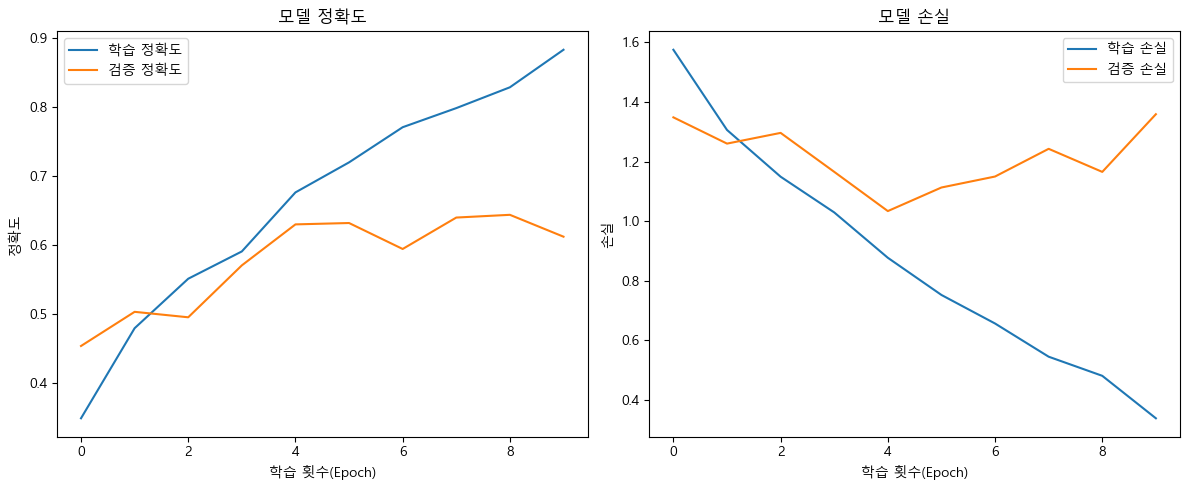

In [16]:
# 학습 결과 그래프

# 학습 정확도와 검증 정확도 그래프 
plt.figure(figsize=(12,5)) # figure(피겨): 그래프 전체 화면 만들기 

# 정확도 그래프 
plt.subplot(1,2,1) # subplot(서브플랏): 화면을 1행 2열로 나누고 첫 번째 그래프 선택
plt.plot(history.history["accuracy"], label="학습 정확도")   # plot(플랏): 학습 정확도 그래프 그리기
plt.plot(history.history["val_accuracy"], label="검증 정확도") # val(밸): validation(밸리데이션, 검증) 데이터의 정확도
plt.title("모델 정확도")
plt.xlabel("학습 횟수(Epoch)")
plt.ylabel("정확도")
plt.legend() # legend(레전드): 그래프 선의 의미를 표시하는 범례

# 손실 그래프 
plt.subplot(1,2,2)  # 두 번째 그래프 선택
plt.plot(history.history["loss"], label="학습 손실")
plt.plot(history.history["val_loss"], label="검증 손실")
plt.title("모델 손실")
plt.xlabel("학습 횟수(Epoch)")
plt.ylabel("손실")
plt.legend()

plt.tight_layout()# tight_layout(타이트 레이아웃): 그래프 요소가 겹치지 않도록 정리
plt.show()


In [17]:
# 모델평가 
# evaluate(이밸류에이트): 모델의 성능을 평가하다
# val_ds(밸리데이션 데이터셋): 학습 중 직접 학습에 사용하지 않은 검증용 이미지

val_loss, val_accuracy = model.evaluate(val_ds)

#결과출력
print(f"검증 손실(Validation Loss): {val_loss:.4f}")
print(f"검증 정확도(Validation Accuracy): {val_accuracy * 100:.2f}%")
# .4f: 소수점 아래 4자리까지 표시
# * 100: 비율을 백분율(%)로 변환


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.6119 - loss: 1.3593
검증 손실(Validation Loss): 1.3593
검증 정확도(Validation Accuracy): 61.19%


In [ ]:
# LSTM 에 사용할 데이터 확인

print("학습 데이터 형태:", train_ds.element_spec)
print("검증 데이터 형태:", val_ds.element_spec)
#햄버거 재료 어떤모양으로 준비되어있는지 확인 

학습 데이터 형태: (TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))
검증 데이터 형태: (TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))


In [19]:
# CNN 예측 결과확인

images, labels = next(iter(val_ds)) # 검증 이미지와 정답 가져오기 
predictions = model.predict(images) # 프리딕트 : 이미지예측
predicted_labels = np.argmax(predictions, axis=1) # 아그맥스 : 가장높은확률 선택

print("실제 정답 : ", labels.numpy()[:10])
print("예측 결과 : ", predicted_labels[:10])

# 햄버거 사진 을 보고 종류를 맞힌 뒤 실제 정답과 비교하기
# 결과: 정확도 90% 


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step
실제 정답 :  [1 4 0 1 3 4 1 2 3 0]
예측 결과 :  [1 4 3 1 3 4 1 1 3 0]


In [20]:
# 검증 데이터 전체 예측 정확도

correct = 0 #정답 개수
total = 0 # 전체 데이터 개수

for images, labels in val_ds:
    predictions = model.predict(images, verbose =0) #이미지 예측 
    predicted_labels = np.argmax(predictions, axis=1) # 가장 높은확률 선택
    
    correct += np.sum(predicted_labels == labels.numpy())# 맞힌 개수 누적
    total += len(labels) # 전체 개수 누적
    
accuracy = correct / total # 정확도 계산 

print(f"전체 검증 정확도: {accuracy *100:.2f}%")

# 전체 손님 주문을 얼마나 정확하게 맞혔는지 확인 
# 정확도 : 67.52% 전체 데이터에서는 정확도가 낮음. 일부 이미지만 잘 맞혔을 가능성 염두

전체 검증 정확도: 61.19%


In [21]:
# 혼동행렬로 분리수거 종류별 예측 결과 확인

from sklearn.metrics import confusion_matrix, classification_report 
# confusion_matrix(컨퓨전 매트릭스): 실제 정답과 예측 결과 비교
# classification_report(클래시피케이션 리포트): 종류별 성능 확인

all_true = [] #실제 정답 저장
all_pred = [] # AI 예측 결과 저장

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0) # 검증 이미지 예측
    predicted_labels = np.argmax(predictions, axis=1) #녹은확률 선택
    
    all_true.extend(labels.numpy()) # 실제 정답 누적 extend 목록에 :여러 데이터 추가
    all_pred.extend(predicted_labels) # 예층 결과 누적
    
cm = confusion_matrix(all_true, all_pred) #혼동 행렬 생성
print("홍동행렬:\n", cm)

# 68.76,37,95,51,14 정답

    

홍동행렬:
 [[57  2  7  3 11  3]
 [ 2 71  6  3 15  6]
 [ 0 20 38  4  9  7]
 [ 5 11 19 76 11  2]
 [ 3 18 10  5 52  0]
 [ 0  9  1  0  4 15]]


In [22]:
# 종류별 예측 성능 확인

print(classification_report(all_true, all_pred))

              precision    recall  f1-score   support

           0       0.85      0.69      0.76        83
           1       0.54      0.69      0.61       103
           2       0.47      0.49      0.48        78
           3       0.84      0.61      0.71       124
           4       0.51      0.59      0.55        88
           5       0.45      0.52      0.48        29

    accuracy                           0.61       505
   macro avg       0.61      0.60      0.60       505
weighted avg       0.64      0.61      0.62       505



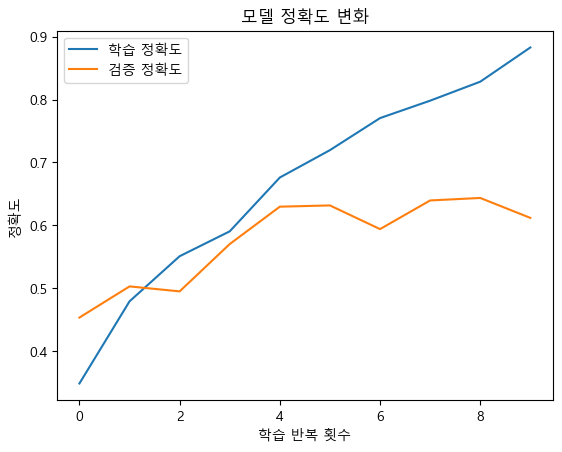

In [23]:
# 학습 과정의 정확도 변화 확인

plt.plot(history.history['accuracy'], label='학습 정확도') #학습 정확도
plt.plot(history.history['val_accuracy'], label='검증 정확도') # 검증 정확도

plt.title('모델 정확도 변화')
plt.xlabel('학습 반복 횟수')
plt.ylabel('정확도')
plt.legend()
plt.show()


In [24]:
# 모델 저장 
model.save('recycle_model.keras')

In [25]:
# 모델 불러오기
loaded_model = tf.keras.models.load_model('recycle_model.keras')

print("저장된 모델 불러오기 완료!")

저장된 모델 불러오기 완료!


In [26]:
# 분리수거 종류 이름 지정
class_names =['종이상자', '유리', '금속', '종이', '플라스틱', '일반쓰레기']


In [27]:
# 새로운 이미지의 분리수거 종류 예측 함수 

def predict_image(image_path): # 이미지 경로를 받아 분리수거 종류 예측
    
    img = tf.keras.utils.load_img(image_path, target_size=(128,128)) # 이미지크기 변경
    img_array = tf.keras.utils.img_to_array(img) #이미지를 숫자로 배열 변환 
    img_array = img_array /255.0  # 0~1사이 정규화
    img_array = np.expand_dims(img_array, axis = 0) #이미지묶음 차원추가 
    prediction = loaded_model.predict(img_array, verbose = 0) # 저장된 모델로 예측
    predicted_index = np.argmax(prediction[0]) 
    
    print("예측 결과:", class_names[predicted_index]) #분리 수거 종류 출력
    print("예측 확률:", round(float(prediction[0][predicted_index]) * 100, 2), "%")
    # 백분율
    

In [28]:
# 새로운 이미지 선택 및 분리수거 예측 실행

from tkinter import Tk, filedialog  # 파일 선택창 기능 불러오기

root = Tk()  # 파일 선택창 생성
root.withdraw()  # 빈 창 숨기기
root.attributes('-topmost', True)  # 선택창을 화면 맨 위로
root.update()  # 바로 화면에 그리기

image_path = filedialog.askopenfilename(
    title="분리수거 이미지 선택",
    filetypes=[("이미지 파일", "*.jpg *.jpeg *.png")]
)  # 예측할 이미지 선택

root.destroy()  # 파일 선택창 종료

if image_path:
    print("선택한 이미지:", image_path)
    predict_image(image_path)  # 분리수거 종류 예측
else:
    print("이미지를 선택하지 않았습니다.")

이미지를 선택하지 않았습니다.


In [40]:
# 파일 선택창 대신 경로 직접 써서 예측하기

image_path = r"C:\Users\human-01\Downloads\test.jpg" # 여기에 예측할 사진 경로 붙여넣기

predict_image(image_path) # 분리수거 종류 예측

UnidentifiedImageError: cannot identify image file <_io.BytesIO object at 0x0000018AE88192B0>

In [41]:
from PIL import Image

img = Image.open(r"C:\Users\human-01\Downloads\test.jpg")
print("이미지 형식:", img.format)
print("이미지 크기:", img.size)

UnidentifiedImageError: cannot identify image file 'C:\\Users\\human-01\\Downloads\\test.jpg'

In [44]:
image_path = r"C:\Users\human-01\Downloads\test2.jpg"

predict_image(image_path)

UnidentifiedImageError: cannot identify image file <_io.BytesIO object at 0x0000018AEEA63240>

In [ ]:
import os 

path=  r"C:\Users\human-01\Downloads\test2.jpg"  # 확인할 사진 파일의 위치
print("파일 크기:", os.path.getsize(path), "bytes")  # 파일이 실제로 얼마나 큰지 확인

with open(path, "rb")as f: #파일을 읽기 전용으로 열기 (rb = 바이너리 읽기)
    print ("파일 시작 부분:", f.read(20)) #파일의 첫 20바티를 읽어 실제 파일형식 확인 
    
    #실제 이미지 데이터 들어있는지 확인 

파일 크기: 1047364 bytes
파일 시작 부분: b'<!DOCTYPE html>\n<!--'
